# Figure05S2 — When Do Collapsing Bounds Help?

## Summary

For all three mixed-block (MX) reward structures used in the pigeon task, the optimal
decision boundary for an SNR-agnostic observer is **flat or increasing**, not collapsing.
This holds for the actual pigeon-task SNR pair {μ=0.05, μ=0.15}.

Adding zero-SNR (μ=0) trials to the mix can shift the global optimum toward collapsing, but
the **reward-rate advantage over flat is negligible in absolute terms** — well under
0.001 coins/step in all cases. In *relative* terms the advantage can reach several percent
in blocks with very low baseline reward rate: e.g. +4.3% for Block 2 with zero-SNR trials,
where absolute rates are only ~0.007 coins/step (flat≈0.00663, coll≈0.00691 coins/step).

### Why collapsing does NOT help for two non-zero SNRs

For each reward structure, the optimal flat bound is monotonically decreasing in μ: harder
(lower-μ) trials require a higher position threshold to accumulate sufficient evidence.
An agnostic observer facing a mixture therefore benefits from an **increasing** bound —
start lower to capture early easy-trial exits, then rise to handle the harder trials that
persist.  A collapsing bound does the opposite and is suboptimal.

### Why adding zero-SNR gives only a slight advantage

Zero-SNR (μ=0) trials are informationally useless: the walk is symmetric, so the evidence
never converges.  When such trials persist to late timesteps, a collapsing bound reduces
further wasteful accumulation.  But in the pigeon task the effect is tiny because the
proportion of zero-SNR survivors at late steps is small and the non-zero-SNR landscape
strongly favors increasing bounds.

---

**Bound parameterisation:**  $B(t) = B_{ini} + (B_{fin}-B_{ini})\cdot\min(t,\,T_{change})/T_{change}$

The (B_ini, B_fin) grid covers all cases on a single heatmap:
- **Diagonal** (B_fin = B_ini): flat bound
- **Upper-left** (B_fin > B_ini): increasing bound
- **Lower-right** (B_fin < B_ini): collapsing bound

In [1]:
import sys
sys.path.insert(0, '..')

import numpy as np
import matplotlib
import matplotlib.pyplot as plt

from pigeon.pathDefaults import FIGURES_DIR
from pigeon.plotting import FONT_RC, add_panel_label, CONDITION_LABELS

# ── Task parameters ───────────────────────────────────────────────────────────
G_STD     = 0.15    # noise SD per step (shared across all SNR levels)
MAX_STEPS = 300     # trial cutoff; long enough that zero-SNR trials can accumulate
T_CHANGE  = 30      # steps over which the bound ramps from B_ini to B_fin
N_TRIALS  = 60_000  # trajectories per SNR level
ITI       = 0       # inter-trial interval (steps)

# ── Block reward structures ───────────────────────────────────────────────────
# Matches pigeon.simulation BLOCK_DEFAULTS entries 1-3:
#   1: coins_gained=1, coins_lost=0, steps_lost=0   (gain only)
#   2: coins_gained=1, coins_lost=4, steps_lost=0   (coin penalty)
#   3: coins_gained=1, coins_lost=0, steps_lost=30  (time-out penalty)
BD1 = dict(coins_gained=1, coins_lost=0, steps_lost=0)
BD2 = dict(coins_gained=1, coins_lost=4, steps_lost=0)
BD3 = dict(coins_gained=1, coins_lost=0, steps_lost=30)

BLOCK_DEFS = {1: BD1, 2: BD2, 3: BD3}

# ── Bound grid ────────────────────────────────────────────────────────────────
# 20 evenly-spaced values; (B_ini, B_fin) ∈ RR_BOUNDS² → 20×20 = 400 grid cells.
RR_BOUNDS = np.arange(0.01, 0.81, 0.04)
n = len(RR_BOUNDS)

# Matrix indexing: rr_matrix[fin_idx, ini_idx]
# With imshow(origin='lower'): x-axis = ini_idx, y-axis = fin_idx.
# Upper-left  (fin_idx > ini_idx, B_fin > B_ini): increasing — above the diagonal
# Lower-right (fin_idx < ini_idx, B_fin < B_ini): collapsing — below the diagonal
COLL_MASK = np.triu(np.ones((n, n), bool), k=1)   # ini_idx > fin_idx → collapsing
INCR_MASK = np.tril(np.ones((n, n), bool), k=-1)  # fin_idx > ini_idx → increasing

rng = np.random.default_rng(42)

In [2]:
print("Generating trajectories (one set reused across all blocks and conditions)...")
trajs = {}   # trajs[mu] → (N_TRIALS, MAX_STEPS+1) float32 cumulative DV array
ndts  = {}   # ndts[mu]  → (N_TRIALS,) int array of non-decision times

for mu in [0.0, 0.05, 0.15]:
    noise = rng.normal(mu, G_STD, (N_TRIALS, MAX_STEPS))
    DV = np.concatenate(
        [np.zeros((N_TRIALS, 1)), np.cumsum(noise, axis=1)], axis=1
    ).astype(np.float32)
    trajs[mu] = DV
    ndts[mu]  = rng.integers(0, 2, N_TRIALS)   # uniform NDT ∈ {0, 1}
    print(f"  μ={mu:.2f}  {N_TRIALS:,} trials  ({DV.nbytes/1e6:.0f} MB)")


Generating trajectories (one set reused across all blocks and conditions)...
  μ=0.00  60,000 trials  (72 MB)
  μ=0.05  60,000 trials  (72 MB)
  μ=0.15  60,000 trials  (72 MB)


In [3]:
def compute_rr_matrix(mu_list, bd, iti=ITI):
    """
    Compute the (B_ini, B_fin) reward-rate matrix for a mixture of SNR levels.

    All SNR levels in mu_list use the same time-varying bound on every trial.
    Handles coins_lost (coin penalty) and steps_lost (time-out penalty) for
    incorrect trials.  Returns rr_matrix[fin_idx, ini_idx].
    """
    t  = np.arange(MAX_STEPS, dtype=np.float32)
    rm = np.zeros((n, n))
    steps_lost = bd.get('steps_lost', 0)

    for ini_idx, B_ini in enumerate(RR_BOUNDS):
        for fin_idx, B_fin in enumerate(RR_BOUNDS):
            frac = np.minimum(t, T_CHANGE) / T_CHANGE
            B_t  = (B_ini + (B_fin - B_ini) * frac).astype(np.float32)

            tc, ts = 0.0, 0.0

            for mu in mu_list:
                DV, ndt = trajs[mu], ndts[mu]
                N = len(ndt)

                # First time |DV| ≥ B_t; use MAX_STEPS if threshold never crossed.
                crossed = np.abs(DV[:, 1:]) >= B_t[None, :]
                any_c   = crossed.any(axis=1)
                si      = np.where(any_c, np.argmax(crossed, axis=1) + 1, MAX_STEPS)

                # Correct if DV is on the positive side at the stopping step.
                correct = DV[np.arange(N), si] > 0

                coins = np.where(correct, bd['coins_gained'], -bd['coins_lost'])
                extra = np.where(correct, 0, steps_lost)   # time-out for incorrect

                tc += coins.sum()
                ts += (si + ndt + iti + 1 + extra).sum()

            rm[fin_idx, ini_idx] = tc / ts
    return rm


def summarize(rm):
    """Return (flat_best, coll_best, incr_best, b_flat, Bi, Bf, kind) for a matrix."""
    flat_vals = [rm[i, i] for i in range(n)]
    flat = max(flat_vals)
    fi   = int(np.argmax(flat_vals))
    coll = rm[COLL_MASK].max()
    incr = rm[INCR_MASK].max()
    bf, bi = np.unravel_index(rm.argmax(), rm.shape)
    Bi, Bf = RR_BOUNDS[bi], RR_BOUNDS[bf]
    kind = ('collapsing' if Bf < Bi - 1e-9 else
            'increasing' if Bf > Bi + 1e-9 else 'flat')
    return flat, coll, incr, RR_BOUNDS[fi], Bi, Bf, kind

In [4]:
# Compute 6 reward-rate matrices: 3 blocks × {without / with zero-SNR}
RMS = {}

for block, bd in BLOCK_DEFS.items():
    for with_zero in [False, True]:
        mu_list = [0.0, 0.05, 0.15] if with_zero else [0.05, 0.15]
        snr_str = '{0, 0.05, 0.15}' if with_zero else '{0.05, 0.15}'
        print(f"Block {block}, μ ∈ {snr_str} …")
        RMS[(block, with_zero)] = compute_rr_matrix(mu_list, bd)

print("\nDone.  Summary (flat / coll / incr best RR, Δ=coll−flat):")
print(f"  {'Block':<8}  {'SNR cond':<18}  {'global opt':<6}  "
      f"{'flat':>10}  {'coll':>10}  {'incr':>10}  {'Δcoll−flat':>12}")
for block in [1, 2, 3]:
    for with_zero in [False, True]:
        rm  = RMS[(block, with_zero)]
        flat, coll, incr, b_flat, Bi, Bf, kind = summarize(rm)
        snr = 'w/ zero-SNR' if with_zero else 'no zero-SNR'
        delta_pct = 100 * (coll - flat) / abs(flat)
        print(f"  Block {block}   {snr:<18}  {kind:<6}  "
              f"{flat:10.5f}  {coll:10.5f}  {incr:10.5f}  {delta_pct:+10.3f}%")


Block 1, μ ∈ {0.05, 0.15} …
Block 1, μ ∈ {0, 0.05, 0.15} …
Block 2, μ ∈ {0.05, 0.15} …
Block 2, μ ∈ {0, 0.05, 0.15} …
Block 3, μ ∈ {0.05, 0.15} …
Block 3, μ ∈ {0, 0.05, 0.15} …

Done.  Summary (flat / coll / incr best RR, Δ=coll−flat):
  Block     SNR cond            global opt        flat        coll        incr    Δcoll−flat
  Block 1   no zero-SNR         flat       0.29285     0.28214     0.29284      -3.655%
  Block 1   w/ zero-SNR         flat       0.26042     0.24613     0.26041      -5.488%
  Block 2   no zero-SNR         increasing     0.10539     0.10536     0.10584      -0.033%
  Block 2   w/ zero-SNR         collapsing     0.00663     0.00691     0.00656      +4.258%
  Block 3   no zero-SNR         increasing     0.11406     0.11378     0.11429      -0.246%
  Block 3   w/ zero-SNR         collapsing     0.06228     0.06243     0.06216      +0.250%


## Formatted supplemental figure

Two rows, three columns:
- **Top row (A–C):** RR heatmap for {μ=0.05, μ=0.15} — the actual pigeon MX task SNRs.
  For all three blocks the global optimum (blue circle) lies on or above the diagonal,
  confirming that flat or increasing bounds are optimal.
- **Bottom row (D–F):** Same blocks with μ=0 added.
  The optimum may shift into the collapsing region, but the reward-rate gain over flat
  (annotated in each panel) is negligible.

Dashed white line = flat bound diagonal. Blue contour = near-optimal plateau (within 5% of
max RR). Filled blue circle = single peak grid point.


1 extra bytes in post.stringData array
'created' timestamp seems very low; regarding as unix timestamp


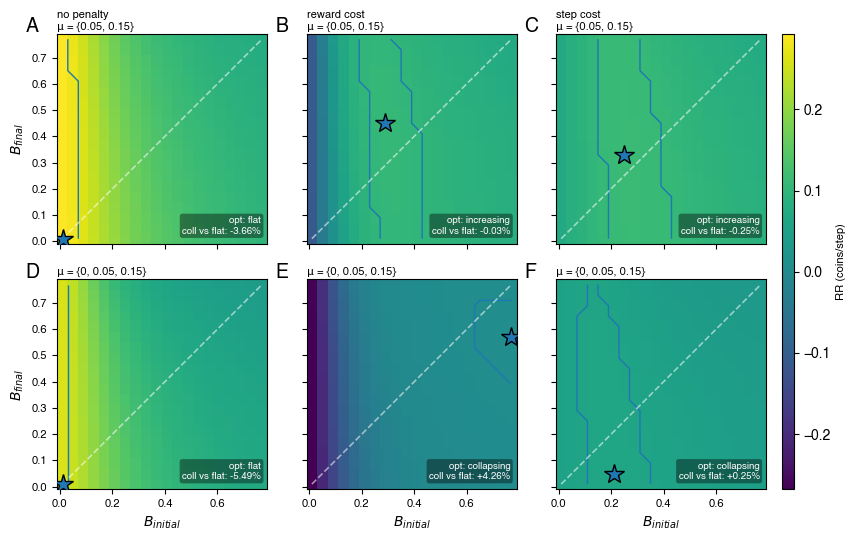

Saved /Users/jigold/Library/CloudStorage/Box-Box/GoldLab/Projects/2025_Pigeon/Figures/Figure05_S02.pdf


In [ ]:
import matplotlib.gridspec as gridspec

CM  = 1 / 2.54
FS  = 10
PSH = 0.9        # vertical panel separation (cm)
PSW = 1.0        # horizontal panel separation (cm)
CBAR_W   = 0.3   # colorbar width (cm)
CBAR_PAD = 0.4   # gap between panel grid and colorbar (cm)

n_rows, n_cols = 2, 3
WID   = 18.0                                     # panel-grid width (cm)
PANEL = (WID - PSW * (n_cols - 1)) / n_cols      # square panel size (cm)
HTS   = [PANEL, PANEL]                           # row heights (cm) — square axes

fig_h  = sum(HTS) + PSH * (n_rows - 1)
fig_w  = WID + CBAR_PAD + CBAR_W
hspace = PSH / np.mean(HTS)
wspace = PSW / PANEL

ROW_SNR = {
    False: 'μ = {0.05, 0.15}',
    True:  'μ = {0, 0.05, 0.15}',
}
LETTERS = [['A', 'B', 'C'], ['D', 'E', 'F']]

half   = (RR_BOUNDS[1] - RR_BOUNDS[0]) / 2
extent = [RR_BOUNDS[0] - half, RR_BOUNDS[-1] + half,
          RR_BOUNDS[0] - half, RR_BOUNDS[-1] + half]
diag   = [RR_BOUNDS[0], RR_BOUNDS[-1]]
b_grid_x, b_grid_y = np.meshgrid(RR_BOUNDS, RR_BOUNDS)

plt.rcParams.update({'font.size': FS, 'axes.labelsize': FS, 'axes.titlesize': FS, **FONT_RC})

# Single reward-rate scale shared across all six panels.
vmin = min(rm.min() for rm in RMS.values())
vmax = max(rm.max() for rm in RMS.values())

fig = plt.figure(figsize=(fig_w * CM, fig_h * CM))
panel_right = WID / fig_w   # fraction of total figure width used by the panel grid
gs = gridspec.GridSpec(n_rows, n_cols, figure=fig,
                       left=0, right=panel_right, bottom=0, top=1,
                       hspace=hspace, wspace=wspace)
axes = np.array([[fig.add_subplot(gs[r, c]) for c in range(n_cols)] for r in range(n_rows)])

im = None
for row, with_zero in enumerate([False, True]):
    for col, block in enumerate([1, 2, 3]):
        ax = axes[row, col]
        rm = RMS[(block, with_zero)]
        flat, coll, incr, b_flat, Bi, Bf, kind = summarize(rm)

        im = ax.imshow(rm, origin='lower', extent=extent, aspect='equal',
                        cmap='viridis', vmin=vmin, vmax=vmax)

        # 95% near-optimal plateau (blue contour) + single peak (filled blue
        # star), matching the RR-landscape summary style used in Figure 6.
        near_opt = (rm >= 0.95 * rm.max()).astype(float)
        ax.contour(b_grid_x, b_grid_y, near_opt, levels=[0.5],
                   colors='tab:blue', linewidths=1, zorder=3)
        ax.plot(Bi, Bf, '*', color='tab:blue', markersize=15,
                markeredgecolor='k', markeredgewidth=1, zorder=5)

        # Flat-bound diagonal
        ax.plot(diag, diag, 'w--', lw=1.2, alpha=0.55, zorder=4)

        ax.tick_params(labelsize=FS - 2)
        if col == 0:
            ax.set_ylabel('$B_{final}$')
        else:
            ax.tick_params(axis='y', labelleft=False)
        if row == n_rows - 1:
            ax.set_xlabel('$B_{initial}$')
        else:
            ax.tick_params(axis='x', labelbottom=False)

        # Column header (condition name, top row only) + SNR condition (shown
        # on every panel).
        letter = LETTERS[row][col]
        title_lines = []
        if row == 0:
            title_lines.append(CONDITION_LABELS[block])
        title_lines.append(ROW_SNR[with_zero])
        ax.set_title('\n'.join(title_lines), fontsize=FS - 2, loc='left', pad=3)
        add_panel_label(ax, letter)

        # Annotation: optimum type + collapsing advantage over flat
        delta_pct = 100 * (coll - flat) / abs(flat) if flat != 0 else float('nan')
        ax.text(
            0.97, 0.04,
            f'opt: {kind}\ncoll vs flat: {delta_pct:+.2f}%',
            transform=ax.transAxes, ha='right', va='bottom',
            fontsize=FS - 3, color='white',
            bbox=dict(boxstyle='round,pad=0.25', fc=(0, 0, 0, 0.4), ec='none'),
        )

# Single colorbar for the whole figure, aligned to the full height of the panel grid.
y0 = axes[-1, 0].get_position().y0
y1 = axes[0, 0].get_position().y1
cax = fig.add_axes([(WID + CBAR_PAD) / fig_w, y0, CBAR_W / fig_w, y1 - y0])
cbar = fig.colorbar(im, cax=cax)
cbar.set_label('RR (coins/step)', fontsize=FS - 2)

out = FIGURES_DIR / 'Figure05_S02.pdf'
fig.savefig(out, dpi=300, bbox_inches='tight')
plt.show()
print(f'Saved {out}')